# Master bias

`author` Julien Morin <julien.morin@umontpellier.fr>

`date` 11 Oct 2023

Reference: *Handbook of CCD Astronomy*, §4.5 and __[CCD Data Reduction Guide #Overscan and bias images](https://www.astropy.org/ccd-reduction-and-photometry-guide/v/dev/notebooks/02-00-Handling-overscan-trimming-and-bias-subtraction.html)__
* build master bias
* check statistical properties
* save as FITS file in the `reference` folder

In [1]:
# import and settings
%matplotlib notebook
import os
import numpy as np
import matplotlib.pyplot as plt
import astropy.io.fits as pf
from astropy.stats import mad_std
from astropy import units as u
from astropy.visualization import ZScaleInterval
import ccdproc as ccdp

In [2]:
# create raw image collection
ifc_raw = ccdp.ImageFileCollection('raw/')

## Master bias

In [3]:
# create bias image collection and print summary and statistics
ifc_bias = ifc_raw.filter(imagetyp='Bias Frame')
# alternatively one could use:
# ifc_bias = ccdp.ImageFileCollection('raw/', glob_include='bias-*.fit*')
bias_summary = ifc_bias.summary
print(bias_summary['file', 'date-obs', 'imagetyp', 'object', 'exposure'])

       file               date-obs         imagetyp  object exposure
------------------ ---------------------- ---------- ------ --------
raw/bias-0001.fits 2020-09-15T20:20:17.39 Bias Frame   bias      0.0
raw/bias-0002.fits 2020-09-15T20:20:23.78 Bias Frame   bias      0.0
raw/bias-0003.fits 2020-09-15T20:20:29.51 Bias Frame   bias      0.0
               ...                    ...        ...    ...      ...
raw/bias-0008.fits 2020-09-15T20:20:58.20 Bias Frame   bias      0.0
raw/bias-0009.fits 2020-09-15T20:21:03.96 Bias Frame   bias      0.0
raw/bias-0010.fits 2020-09-15T20:21:09.70 Bias Frame   bias      0.0
Length = 10 rows


In [4]:
# compute master bias
master_bias = ccdp.combine(ifc_bias.files_filtered(include_path=True), unit='adu', combine='average', mem_limit=512.e6)

INFO:astropy:splitting each image into 4 chunks to limit memory usage to 512000000.0 bytes.


INFO: splitting each image into 4 chunks to limit memory usage to 512000000.0 bytes. [ccdproc.combiner]


In [5]:
# set header keyword (will appear in the saved file)
master_bias.meta['COMBINED'] = True

In [6]:
# ToDo: compare statiscal properties of the bias series and those of the master bias

<IPython.core.display.Javascript object>


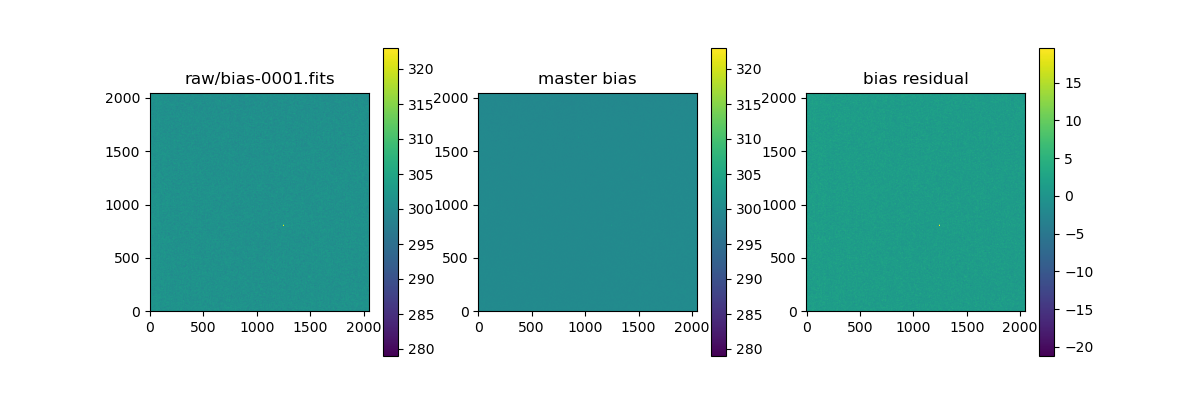

In [7]:
# display 1st bias, master bias and residual
fig = plt.figure(figsize=(12,4))
#
ax1 = fig.add_subplot(131)
ccd_bias1 = ccdp.CCDData.read(ifc_bias.files[0], unit='adu')
interval1 = ZScaleInterval()
z1, z2 = interval1.get_limits(ccd_bias1)
im1 = ax1.imshow(ccd_bias1.data, origin='lower', vmin=z1, vmax=z2)
fig.colorbar(im1)
ax1.set_title(ifc_bias.files[0])
#
ax2 = fig.add_subplot(132)
im2 = ax2.imshow(master_bias.data, origin='lower', vmin=z1, vmax=z2)
fig.colorbar(im2)
ax2.set_title('master bias')
#
ax3 = fig.add_subplot(133)
res_bias = ccd_bias1.data - master_bias.data
interval2 = ZScaleInterval()
z1, z2 = interval2.get_limits(res_bias)
im3 = ax3.imshow(res_bias, origin='lower', vmin=z1, vmax=z2)
fig.colorbar(im3)
ax3.set_title('bias residual')
plt.show()


In [8]:
# ToDo: print statistics of the residual image

In [9]:
# save the master bias in the 'reference' directory
master_bias.write('reference/master_bias.fits', hdu_mask=None, hdu_uncertainty=None, overwrite=True)